# SECT-4451 — Lecture 2 Practical

## Data Exploration & Foundational Math

**Objective:** Explore and clean a student performance dataset, calculate descriptive statistics, visualize data, examine correlations, and practice foundational mathematical operations using Python.

**Libraries:** Pandas, NumPy, and Matplotlib.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
import pandas as pd
import numpy as np


np.random.seed(42)

n = 100

study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)

final_score = (
    (0.5 * study_hours)
    + (0.3 * attendance)
    + (0.2 * previous_mark)
    + np.random.normal(0, 5, n)
)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan

df.loc[99, 'study_hours'] = 50

df.loc[98, 'attendance'] = -10

print(df)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


In [7]:

df.head()


,study_hours,attendance,previous_mark,final_score
0,NaN,70.846293,75.366810,35.178989
1,NaN,80.793547,78.411768,39.481248
2,NaN,81.572855,86.245769,48.605167
3,NaN,76.977227,85.807031,47.329456
4,NaN,83.387143,49.334959,37.044473


In [28]:
print("Dataset shape:", df.shape)


print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (100, 4)

Column names:
['study_hours', 'attendance', 'previous_mark', 'final_score']

Data types:
study_hours      float64
attendance       float64
previous_mark    float64
final_score      float64
dtype: object

Missing values:
study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64


The original dataset contains 100 rows and four columns, so its shape is (100, 4). The cleaned dataset also has a shape of (100, 4).The numerical columns are study_hours, attendance, previous_mark, and final_score.The three input features are study_hours, attendance, and previous_mark.

In [9]:
df.to_csv('student_data.csv', index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [10]:

df.head()

,study_hours,attendance,previous_mark,final_score
0,NaN,70.846293,75.366810,35.178989
1,NaN,80.793547,78.411768,39.481248
2,NaN,81.572855,86.245769,48.605167
3,NaN,76.977227,85.807031,47.329456
4,NaN,83.387143,49.334959,37.044473


In [11]:

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
print(df.describe())

Dataset shape: (100, 4)

Missing values:
study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64

Summary statistics:
       study_hours  attendance  previous_mark  final_score
count    94.000000  100.000000     100.000000   100.000000
mean      5.218916   84.267225      70.973444    42.691957
std       5.014751   13.476443      16.264243     6.086797
min      -0.239490  -10.000000      21.380990    29.163251
25%       3.731467   76.829717      60.168347    38.188854
50%       4.812342   85.841072      71.465436    42.763014
75%       5.744365   90.381704      80.566562    46.688328
max      50.000000  112.201692     127.790972    57.171201


In [12]:

clean_df = df.copy()


study_median = clean_df["study_hours"].median()
clean_df["study_hours"] = clean_df["study_hours"].fillna(study_median)


upper_limit = clean_df.loc[
    clean_df["study_hours"] != 50, "study_hours"
].quantile(0.95)

clean_df["study_hours"] = clean_df["study_hours"].clip(upper=upper_limit)

valid_attendance_median = clean_df.loc[
    clean_df["attendance"] >= 0, "attendance"
].median()

clean_df.loc[
    clean_df["attendance"] < 0, "attendance"
] = valid_attendance_median


print(clean_df.head(10))

print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())

print("\nAttendance range:")
print(clean_df["attendance"].min(), "to", clean_df["attendance"].max())

print("\nMaximum study hours:", clean_df["study_hours"].max())

   study_hours  attendance  previous_mark  final_score
0     4.812342   70.846293      75.366810    35.178989
1     4.812342   80.793547      78.411768    39.481248
2     4.812342   81.572855      86.245769    48.605167
3     4.812342   76.977227      85.807031    47.329456
4     4.812342   83.387143      49.334959    37.044473
5     4.812342   89.040509      55.932624    40.751177
6     7.933747  103.861859      77.725529    57.171201
7     6.534869   86.745778      77.706789    41.874669
8     4.061051   87.575504      77.725715    46.583807
9     6.085120   84.255541     127.790972    52.866454

Missing values after cleaning:
study_hours      0
attendance       0
previous_mark    0
final_score      0
dtype: int64

Attendance range:
65.81228784700959 to 112.20169166589619

Maximum study hours: 7.9337465930071


In [13]:

valid_attendance = clean_df.loc[
    clean_df["attendance"].between(0, 100),
    "attendance"
]

attendance_median = valid_attendance.median()

clean_df.loc[
    ~clean_df["attendance"].between(0, 100),
    "attendance"
] = attendance_median

print("Attendance minimum:", clean_df["attendance"].min())
print("Attendance maximum:", clean_df["attendance"].max())

Attendance minimum: 65.81228784700959
Attendance maximum: 99.53534077157317


In [14]:

numeric_columns = [
    "study_hours",
    "attendance",
    "previous_mark",
    "final_score"
]


print("MEAN")
print(clean_df[numeric_columns].mean())

print("\nMEDIAN")
print(clean_df[numeric_columns].median())

print("\nSTANDARD DEVIATION")
print(clean_df[numeric_columns].std())

MEAN
study_hours       4.760305
attendance       83.779036
previous_mark    70.973444
final_score      42.691957
dtype: float64

MEDIAN
study_hours       4.812342
attendance       85.130019
previous_mark    71.465436
final_score      42.763014
dtype: float64

STANDARD DEVIATION
study_hours       1.777128
attendance        7.607929
previous_mark    16.264243
final_score       6.086797
dtype: float64


In [15]:
statistics = clean_df[numeric_columns].agg(
    ["mean", "median", "std"]
)

statistics


,study_hours,attendance,previous_mark,final_score
mean,4.760305,83.779036,70.973444,42.691957
median,4.812342,85.130019,71.465436,42.763014
std,1.777128,7.607929,16.264243,6.086797


Study hours: The original study-hours data contained missing values and an extreme value of 50. Cleaning these records makes the summary statistics more representative of the typical study hours in the dataset.
Attendance: The original dataset contained an impossible attendance value of -10. Replacing it with the median of valid observations prevents this invalid value from distorting the descriptive statistics.
Final score: Comparing the mean and median of final_score helps reveal whether the distribution is approximately symmetric or skewed. The standard deviation describes how much students' final scores vary around their mean.

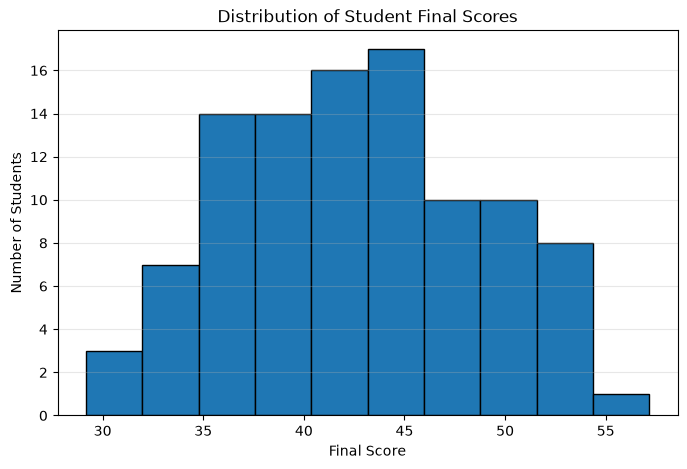

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(
    clean_df["final_score"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Student Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.grid(axis="y", alpha=0.3)

plt.show()

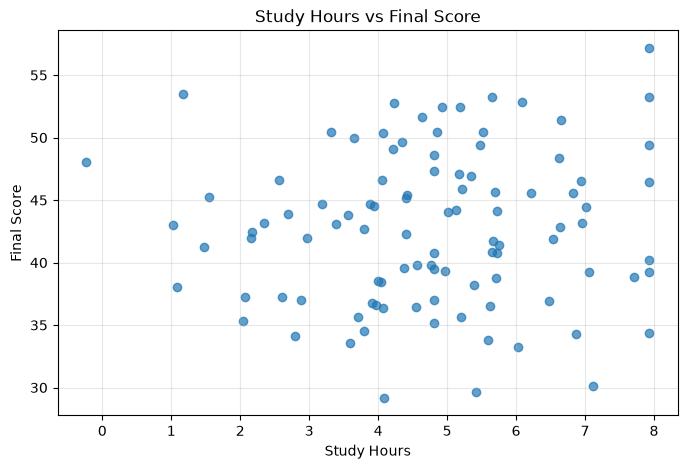

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    clean_df["study_hours"],
    clean_df["final_score"],
    alpha=0.7
)

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")
plt.grid(alpha=0.3)

plt.show()

Histogram of final scores
The histogram shows the distribution of students' final scores. It helps identify the range of scores, the concentration of observations, and whether the distribution appears symmetric or skewed.
Scatter plot of study hours versus final score
The scatter plot helps examine the relationship between study hours and final scores. The general trend is expected to be positive because study hours contribute positively to the formula used to generate final scores. However, the points do not all fall on a straight line because attendance, previous marks, and random variation also affect the scores.

In [18]:
correlation = clean_df[
    ["study_hours", "attendance", "previous_mark", "final_score"]
].corr()

print(correlation)

               study_hours  attendance  previous_mark  final_score
study_hours       1.000000   -0.067475       0.175123     0.058645
attendance       -0.067475    1.000000      -0.089334     0.337711
previous_mark     0.175123   -0.089334       1.000000     0.545478
final_score       0.058645    0.337711       0.545478     1.000000


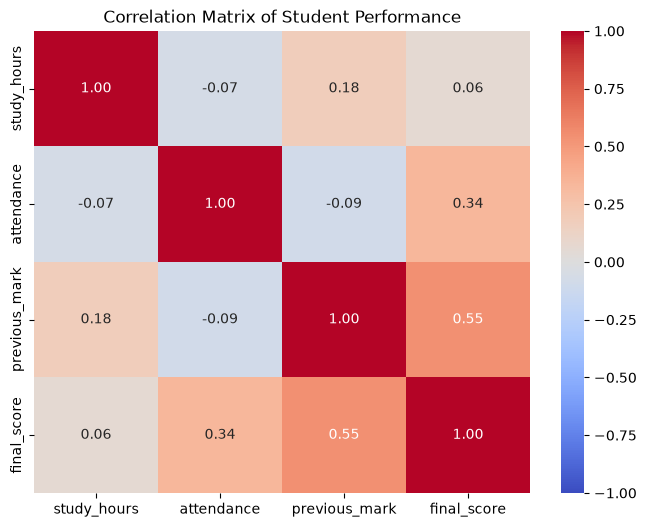

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Student Performance")
plt.show()

The correlation matrix shows the relationships between study hours, attendance, previous marks, and final scores.

The correlation between study hours and final scores is 0.06, indicating a very weak positive linear relationship. Attendance has a positive correlation of 0.34 with final scores, suggesting that higher attendance is associated with higher final scores.
Previous marks have the strongest positive correlation with final scores, at 0.55. This suggests that students with higher previous marks tend to achieve higher final scores. The correlations between study hours and attendance (-0.07), study hours and previous marks (0.18), and attendance and previous marks (-0.09) are weak.Overall, previous marks have the strongest linear association with final scores among the three variables examined. 

In [20]:
correlation = clean_df["study_hours"].corr(
    clean_df["final_score"]
)

print("Pearson correlation coefficient:", round(correlation, 4))

Pearson correlation coefficient: 0.0586


Question 1: If a student studies 10 hours, does the correlation guarantee they will get a specific score?
No correlation does not guarantee that a student who studies 10 hours will receive a specific score. Correlation measures the relationship between two variables across observations, but it does not provide a guaranteed score for an individual student. Final scores may also depend on other factors, such as prior knowledge, study methods, attendance, sleep, and exam difficulty.

Question 2: What is a potential lurking or confounding variable?
Students who already understand the subject may need fewer study hours to achieve high scores, while students who struggle with the material may study longer but still receive lower scores. Prior knowledge could therefore influence both study time and final scores.Other possible factors include sleep quality, study methods, motivation, and exam difficulty.

In [21]:
import numpy as np

x = clean_df.loc[
    0, ["study_hours", "attendance", "previous_mark"]
].to_numpy(dtype=float)

print("Student feature vector x:")
print(x)

Student feature vector x:
[ 4.8123416  70.84629258 75.36681041]


In [22]:

w = np.array([0.5, 0.2, 0.4])
b = 5

print("Weight vector:", w)
print("Bias:", b)

Weight vector: [0.5 0.2 0.4]
Bias: 5


In [23]:

y = np.dot(w, x) + b

print("Student feature vector:", x)
print("Weight vector:", w)
print("Bias:", b)
print("Calculated output y:", round(y, 2))

Student feature vector: [ 4.8123416  70.84629258 75.36681041]
Weight vector: [0.5 0.2 0.4]
Bias: 5
Calculated output y: 51.72


Question 1: What does the weight vector represent in the context of predicting a score?

The weight vector represents the importance and contribution assigned to each input feature when calculating the output. Each weight multiplies its corresponding feature. A larger weight gives that feature a larger contribution per unit, although the actual influence also depends on the feature's scale.

Question 2: Why do we need the bias?

The bias is a constant added to the weighted sum of the input features. It allows the output to be shifted independently of the feature values. Without a bias, the output would be determined only by the weighted sum and would be zero when all input features were zero.

In [25]:

scaled_df = clean_df.copy()

scaled_df["study_hours_scaled"] = (
    clean_df["study_hours"] - clean_df["study_hours"].mean()
) / clean_df["study_hours"].std()

scaled_df["previous_mark_scaled"] = (
    clean_df["previous_mark"] - clean_df["previous_mark"].mean()
) / clean_df["previous_mark"].std()


print(
    scaled_df[
        [
            "study_hours",
            "study_hours_scaled",
            "previous_mark",
            "previous_mark_scaled"
        ]
    ].head(10)
)

   study_hours  study_hours_scaled  previous_mark  previous_mark_scaled
0     4.812342            0.029281      75.366810              0.270124
1     4.812342            0.029281      78.411768              0.457342
2     4.812342            0.029281      86.245769              0.939012
3     4.812342            0.029281      85.807031              0.912037
4     4.812342            0.029281      49.334959             -1.330433
5     4.812342            0.029281      55.932624             -0.924778
6     7.933747            1.785713      77.725529              0.415149
7     6.534869            0.998557      77.706789              0.413997
8     4.061051           -0.393474      77.725715              0.415161
9     6.085120            0.745481     127.790972              3.493401


K-Nearest Neighbors uses distances to identify observations that are close to one another. Without scaling, a feature with a larger numerical range can dominate the distance calculation.In this dataset, study_hours is measured in hours, while previous_mark is measured in marks. Previous marks generally have a much larger numerical range than study hours. Without scaling, differences in previous marks could dominate the distance calculation, making study hours less influential than intended.Standardization gives both features comparable scales, so neither automatically dominates the distance calculation simply because of its units or numerical range